# VCU IMU Baseline Integration

This notebook loads one decoded `LOG####_imu.csv`, finds stationary samples, subtracts the stationary accelerometer and gyro baselines, then integrates adjusted acceleration into velocity and position. If the matching `LOG####_medium.csv` is available, its `speed_mph` column is used to detect rest windows.

## Imports

In [1]:
from pathlib import Path
import re

from IPython.display import clear_output, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None


## User Configuration

In [2]:
# Directory containing decoded LOG####_imu.csv files.
DATA_DIR = r"VCU/June11thTestingDataLog_AfterChargingBattery"

# Accepts 10, "10", "0010", or "LOG0010".
LOG_NUMBER = "LOG0010"

# Leave these as None to auto-select the first and last rest windows.
# Use (start_s, end_s) to force a window in elapsed seconds, for example (0.0, 2.0).
BASELINE_TIME_RANGE_S = None
END_REST_TIME_RANGE_S = None

# Rest detection settings. speed_mph is preferred when LOG####_medium.csv exists.
REST_SPEED_THRESHOLD_MPH = 0.5
MIN_REST_WINDOW_S = 1.0
FALLBACK_WINDOW_S = 2.0

# IMU-only rest detection fallback used when speed_mph is unavailable.
IMU_QUIET_WINDOW_S = 0.75
IMU_QUIET_ACCEL_STD_QUANTILE = 0.20
IMU_QUIET_GYRO_STD_QUANTILE = 0.20

G_TO_MPS2 = 9.80665
MPS_TO_MPH = 2.2369362920544

# Used only for the 2D vehicle rectangle visualization.
VEHICLE_LENGTH_M = 2.9
VEHICLE_WIDTH_M = 1.4
SIMULATION_MAX_FRAMES = 600


## Helper Functions

In [3]:
LOG_ID_RE = re.compile(r"^LOG(?P<num>\d+)$", re.IGNORECASE)
ACCEL_COLS = ["accel_x_g", "accel_y_g", "accel_z_g"]
GYRO_COLS = ["gyro_x_dps", "gyro_y_dps", "gyro_z_dps"]
AXES = ["x", "y", "z"]


def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "VCU").exists() and (path / "README.md").exists():
            return path
    return start


REPO_ROOT = find_repo_root()


def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
        REPO_ROOT / "VCU" / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()


def normalize_log_id(log_number):
    text = str(log_number).strip()
    match = LOG_ID_RE.match(text)
    if match:
        return f"LOG{int(match.group('num')):04d}"
    if text.isdigit():
        return f"LOG{int(text):04d}"
    raise ValueError(f"Could not parse LOG number from {log_number!r}")


def stream_path(data_dir, log_id, stream):
    return resolve_data_dir(data_dir) / f"{log_id}_{stream}.csv"


def load_numeric_csv(path, required_columns=None):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Log file not found: {path}")

    df = pd.read_csv(path)
    required_columns = required_columns or []
    missing = [column for column in required_columns if column not in df.columns]
    if missing:
        raise ValueError(f"{path.name} is missing required columns: {missing}")

    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="ignore")
    return df


def prepare_imu_df(df):
    df = df.copy()
    numeric_columns = ["t_ms", *ACCEL_COLS, *GYRO_COLS]
    for column in numeric_columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    df = df.dropna(subset=numeric_columns).sort_values("t_ms").drop_duplicates("t_ms")
    df = df.reset_index(drop=True)
    df.insert(1, "elapsed_s", (df["t_ms"] - df["t_ms"].iloc[0]) / 1000.0)
    return df


def attach_speed_if_available(imu_df, data_dir, log_id):
    medium_path = stream_path(data_dir, log_id, "medium")
    if not medium_path.exists():
        return imu_df, None

    medium = load_numeric_csv(medium_path)
    if "t_ms" not in medium.columns or "speed_mph" not in medium.columns:
        return imu_df, None

    medium = medium[["t_ms", "speed_mph"]].copy()
    medium["t_ms"] = pd.to_numeric(medium["t_ms"], errors="coerce")
    medium["speed_mph"] = pd.to_numeric(medium["speed_mph"], errors="coerce")
    medium = medium.dropna().sort_values("t_ms").drop_duplicates("t_ms")
    if medium.empty:
        return imu_df, None

    imu_df = imu_df.copy()
    imu_df["speed_mph"] = np.interp(
        imu_df["t_ms"].to_numpy(),
        medium["t_ms"].to_numpy(),
        medium["speed_mph"].to_numpy(),
        left=medium["speed_mph"].iloc[0],
        right=medium["speed_mph"].iloc[-1],
    )
    return imu_df, medium_path


def rolling_sample_count(elapsed_s, window_s):
    dt = np.diff(np.asarray(elapsed_s, dtype=float))
    positive_dt = dt[dt > 0]
    if positive_dt.size == 0:
        return 3
    return max(3, int(round(window_s / np.median(positive_dt))))


def imu_quiet_rest_mask(df):
    window_samples = rolling_sample_count(df["elapsed_s"], IMU_QUIET_WINDOW_S)
    min_periods = max(3, window_samples // 2)
    accel_norm = np.linalg.norm(df[ACCEL_COLS].to_numpy(), axis=1)
    gyro_norm = np.linalg.norm(df[GYRO_COLS].to_numpy(), axis=1)

    accel_std = pd.Series(accel_norm).rolling(
        window_samples, center=True, min_periods=min_periods
    ).std()
    gyro_std = pd.Series(gyro_norm).rolling(
        window_samples, center=True, min_periods=min_periods
    ).std()

    accel_limit = accel_std.quantile(IMU_QUIET_ACCEL_STD_QUANTILE)
    gyro_limit = gyro_std.quantile(IMU_QUIET_GYRO_STD_QUANTILE)
    return (accel_std <= accel_limit).fillna(False) & (gyro_std <= gyro_limit).fillna(False)


def time_range_mask(df, time_range_s):
    if time_range_s is None:
        return None
    start_s, end_s = time_range_s
    elapsed = df["elapsed_s"]
    if start_s is None:
        start_s = elapsed.min()
    if end_s is None:
        end_s = elapsed.max()
    mask = (elapsed >= start_s) & (elapsed <= end_s)
    if not mask.any():
        raise ValueError(f"No samples found in requested time range {time_range_s}")
    return mask.to_numpy(dtype=bool)


def contiguous_true_segments(mask, elapsed_s):
    mask = np.asarray(mask, dtype=bool)
    elapsed_s = np.asarray(elapsed_s, dtype=float)
    if mask.size == 0 or not mask.any():
        return []

    starts = np.flatnonzero(mask & np.r_[True, ~mask[:-1]])
    ends = np.flatnonzero(mask & np.r_[~mask[1:], True])
    segments = []
    for start_idx, end_idx in zip(starts, ends):
        segments.append(
            {
                "start_idx": int(start_idx),
                "end_idx": int(end_idx),
                "start_s": float(elapsed_s[start_idx]),
                "end_s": float(elapsed_s[end_idx]),
                "duration_s": float(elapsed_s[end_idx] - elapsed_s[start_idx]),
                "samples": int(end_idx - start_idx + 1),
            }
        )
    return segments


def fallback_edge_window(df, which):
    elapsed = df["elapsed_s"].to_numpy()
    if which == "first":
        return elapsed <= min(elapsed[0] + FALLBACK_WINDOW_S, elapsed[-1])
    if which == "last":
        return elapsed >= max(elapsed[-1] - FALLBACK_WINDOW_S, elapsed[0])
    raise ValueError(f"Unknown edge window selector: {which}")


def select_rest_window(df, rest_mask, which):
    segments = contiguous_true_segments(rest_mask, df["elapsed_s"])
    candidates = [segment for segment in segments if segment["duration_s"] >= MIN_REST_WINDOW_S]
    if candidates:
        segment = candidates[0] if which == "first" else candidates[-1]
        mask = np.zeros(len(df), dtype=bool)
        mask[segment["start_idx"] : segment["end_idx"] + 1] = True
        return mask, segment, False

    mask = fallback_edge_window(df, which)
    selected_segments = contiguous_true_segments(mask, df["elapsed_s"])
    return mask, selected_segments[0], True


def cumulative_trapezoid(y, x):
    y = np.asarray(y, dtype=float)
    x = np.asarray(x, dtype=float)
    if y.ndim == 1:
        y = y[:, None]
    if len(x) != len(y):
        raise ValueError("x and y must have the same length")
    if len(x) == 0:
        return np.empty_like(y)
    increments = 0.5 * (y[1:] + y[:-1]) * np.diff(x)[:, None]
    return np.vstack([np.zeros((1, y.shape[1])), np.cumsum(increments, axis=0)])


def vector_summary(series, units):
    values = pd.Series(series, dtype=float)
    norm = float(np.linalg.norm(values.to_numpy()))
    return pd.Series({**values.to_dict(), "norm": norm}, name=units)


def normalize_vector(vector, *, name="vector"):
    vector = np.asarray(vector, dtype=float)
    norm = np.linalg.norm(vector)
    if not np.isfinite(norm) or norm <= 0:
        raise ValueError(f"Cannot normalize {name}; norm is {norm}")
    return vector / norm


def project_to_plane(vector, plane_normal):
    vector = np.asarray(vector, dtype=float)
    plane_normal = normalize_vector(plane_normal, name="plane_normal")
    return vector - np.dot(vector, plane_normal) * plane_normal


def principal_ground_direction(vectors, ground_normal):
    projected = np.array([project_to_plane(vector, ground_normal) for vector in vectors])
    projected = projected[np.linalg.norm(projected, axis=1) > 1e-9]
    if len(projected) < 2:
        raise ValueError("Not enough horizontal motion samples to estimate heading")

    _, _, vh = np.linalg.svd(projected - projected.mean(axis=0), full_matrices=False)
    return normalize_vector(project_to_plane(vh[0], ground_normal), name="principal direction")


def determine_vehicle_heading_in_imu_space(
    position_vectors_m,
    accel_vectors_mps2,
    baseline_accel_vector_g,
    rest_mask=None,
    min_displacement_m=0.25,
):
    """Estimate vehicle forward heading as a unit vector in IMU xyz coordinates.

    The accelerometer baseline defines the ground-plane normal. The preferred
    heading estimate is the net horizontal displacement. If that displacement is
    too small, the function falls back to the dominant horizontal acceleration
    direction during non-rest samples.
    """
    position_vectors_m = np.asarray(position_vectors_m, dtype=float)
    accel_vectors_mps2 = np.asarray(accel_vectors_mps2, dtype=float)
    ground_normal_imu = normalize_vector(baseline_accel_vector_g, name="baseline acceleration")

    displacement_imu = project_to_plane(position_vectors_m[-1] - position_vectors_m[0], ground_normal_imu)
    displacement_norm_m = np.linalg.norm(displacement_imu)
    if displacement_norm_m >= min_displacement_m:
        forward_imu = normalize_vector(displacement_imu, name="net horizontal displacement")
        method = "net horizontal displacement"
    else:
        if rest_mask is None:
            moving_mask = np.ones(len(accel_vectors_mps2), dtype=bool)
        else:
            moving_mask = ~np.asarray(rest_mask, dtype=bool)
        forward_imu = principal_ground_direction(accel_vectors_mps2[moving_mask], ground_normal_imu)
        signed_accel = accel_vectors_mps2[moving_mask] @ forward_imu
        if np.nanmean(signed_accel) < 0:
            forward_imu = -forward_imu
        method = "dominant horizontal acceleration"

    right_imu = normalize_vector(np.cross(forward_imu, ground_normal_imu), name="vehicle right")
    forward_imu = normalize_vector(project_to_plane(forward_imu, ground_normal_imu), name="vehicle forward")

    return {
        "forward_imu": forward_imu,
        "right_imu": right_imu,
        "ground_normal_imu": ground_normal_imu,
        "method": method,
        "net_horizontal_displacement_m": displacement_norm_m,
    }


def heading_table_from_solution(heading_solution):
    return pd.DataFrame(
        {
            "vehicle_forward": heading_solution["forward_imu"],
            "vehicle_right": heading_solution["right_imu"],
            "ground_normal": heading_solution["ground_normal_imu"],
        },
        index=["IMU x", "IMU y", "IMU z"],
    )


def rectangle_corners(center_xy, heading_rad, length_m, width_m):
    center_xy = np.asarray(center_xy, dtype=float)
    forward = np.array([np.cos(heading_rad), np.sin(heading_rad)])
    right = np.array([-np.sin(heading_rad), np.cos(heading_rad)])
    half_length = length_m / 2.0
    half_width = width_m / 2.0
    corners = np.array(
        [
            center_xy + half_length * forward + half_width * right,
            center_xy + half_length * forward - half_width * right,
            center_xy - half_length * forward - half_width * right,
            center_xy - half_length * forward + half_width * right,
        ]
    )
    return np.vstack([corners, corners[0]])


def equal_axis_limits(x, y, pad_m=2.0):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    finite = np.isfinite(x) & np.isfinite(y)
    if not finite.any():
        return (-1, 1), (-1, 1)
    x_min, x_max = float(np.nanmin(x[finite])), float(np.nanmax(x[finite]))
    y_min, y_max = float(np.nanmin(y[finite])), float(np.nanmax(y[finite]))
    x_center = 0.5 * (x_min + x_max)
    y_center = 0.5 * (y_min + y_max)
    span = max(x_max - x_min, y_max - y_min, 1.0) + 2 * pad_m
    half_span = span / 2.0
    return (x_center - half_span, x_center + half_span), (y_center - half_span, y_center + half_span)


## Load One Log

In [4]:
log_id = normalize_log_id(LOG_NUMBER)
data_dir = resolve_data_dir(DATA_DIR)
imu_path = stream_path(data_dir, log_id, "imu")

imu = load_numeric_csv(imu_path, required_columns=["t_ms", *ACCEL_COLS, *GYRO_COLS])
imu = prepare_imu_df(imu)
imu, speed_path = attach_speed_if_available(imu, data_dir, log_id)

print(f"Loaded {imu_path}")
print(f"Rows: {len(imu):,}")
print(f"Elapsed time: {imu['elapsed_s'].iloc[0]:.3f} s to {imu['elapsed_s'].iloc[-1]:.3f} s")
if speed_path is not None:
    print(f"Using speed_mph from {speed_path.name} for rest detection")
else:
    print("No matching speed_mph stream found; using IMU quiet-window rest detection")

display(imu.head())


Loaded C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery\LOG0010_imu.csv
Rows: 18,897
Elapsed time: 0.000 s to 199.095 s
Using speed_mph from LOG0010_medium.csv for rest detection


,t_ms,elapsed_s,accel_x_g,accel_y_g,accel_z_g,gyro_x_dps,gyro_y_dps,gyro_z_dps,imu_temp_c,speed_mph
0,3280,0.00,0.2004,-0.0433,0.8828,-6.11,8.05,0.02,23.00,0.0
1,3290,0.01,0.2136,-0.0348,0.8798,-6.03,7.33,-0.03,23.00,0.0
2,3300,0.02,0.2021,-0.0403,0.8848,-6.08,6.75,0.00,23.02,0.0
3,3310,0.03,0.2231,-0.0409,0.9000,-6.14,8.70,-0.02,23.02,0.0
4,3320,0.04,0.2224,-0.0375,0.8947,-6.17,7.18,-0.09,23.02,0.0


In [6]:
min_time = imu["t_ms"].iloc[0] / 1000
max_time = imu["t_ms"].iloc[-1] / 1000

print(f"{min_time=}")
print(f"{max_time=}")

min_time=3.28
max_time=202.375


## Detect Rest Windows And Calculate Baselines

In [16]:
manual_baseline_mask = time_range_mask(imu, [0, 20.0])
manual_end_rest_mask = time_range_mask(imu, [max_time - min_time - 20.0, max_time - min_time])

if "speed_mph" in imu.columns:
    rest_mask = (imu["speed_mph"].abs() <= REST_SPEED_THRESHOLD_MPH).to_numpy(dtype=bool)
    rest_source = f"abs(speed_mph) <= {REST_SPEED_THRESHOLD_MPH}"
else:
    rest_mask = imu_quiet_rest_mask(imu).to_numpy(dtype=bool)
    rest_source = "quiet IMU rolling standard deviation"

if manual_baseline_mask is not None:
    baseline_mask = manual_baseline_mask
    baseline_segment = contiguous_true_segments(baseline_mask, imu["elapsed_s"])[0]
    baseline_fallback = False
else:
    baseline_mask, baseline_segment, baseline_fallback = select_rest_window(imu, rest_mask, "first")

if manual_end_rest_mask is not None:
    end_rest_mask = manual_end_rest_mask
    end_rest_segment = contiguous_true_segments(end_rest_mask, imu["elapsed_s"])[0]
    end_rest_fallback = False
else:
    end_rest_mask, end_rest_segment, end_rest_fallback = select_rest_window(imu, rest_mask, "last")

baseline_df = imu.loc[baseline_mask]
end_rest_df = imu.loc[end_rest_mask]

baseline_accel_g = baseline_df[ACCEL_COLS].mean()
baseline_gyro_dps = baseline_df[GYRO_COLS].mean()

print(f"Rest detection source: {rest_source}")
print(
    "Baseline window: "
    f"{baseline_segment['start_s']:.3f} s to {baseline_segment['end_s']:.3f} s "
    f"({baseline_segment['samples']:,} samples)"
    + (" [fallback]" if baseline_fallback else "")
)
print(
    "End-rest window: "
    f"{end_rest_segment['start_s']:.3f} s to {end_rest_segment['end_s']:.3f} s "
    f"({end_rest_segment['samples']:,} samples)"
    + (" [fallback]" if end_rest_fallback else "")
)
if end_rest_segment["end_idx"] < len(imu) - 1:
    print("Warning: selected end-rest window does not include the final IMU sample.")

print("\nBaseline acceleration vector (g):")
print(vector_summary(baseline_accel_g, "g").to_string(float_format=lambda value: f"{value:.6f}"))
print("\nBaseline angular velocity vector (deg/s):")
print(vector_summary(baseline_gyro_dps, "deg/s").to_string(float_format=lambda value: f"{value:.6f}"))


Rest detection source: abs(speed_mph) <= 0.5
Baseline window: 0.000 s to 19.995 s (1,995 samples)
End-rest window: 179.101 s to 199.095 s (1,996 samples)

Baseline acceleration vector (g):
accel_x_g    0.210809
accel_y_g   -0.039938
accel_z_g    0.886919
norm         0.912503

Baseline angular velocity vector (deg/s):
gyro_x_dps   -6.096927
gyro_y_dps    7.769308
gyro_z_dps   -0.044261
norm          9.876064


## Subtract Baseline Vectors

In [17]:
imu_adjusted = imu.copy()

accel_adj_g_cols = []
accel_adj_mps2_cols = []
gyro_adj_dps_cols = []
gyro_adj_radps_cols = []

for axis, source_col in zip(AXES, ACCEL_COLS):
    adj_g_col = f"accel_{axis}_adj_g"
    adj_mps2_col = f"accel_{axis}_adj_mps2"
    imu_adjusted[adj_g_col] = imu_adjusted[source_col] - baseline_accel_g[source_col]
    imu_adjusted[adj_mps2_col] = imu_adjusted[adj_g_col] * G_TO_MPS2
    accel_adj_g_cols.append(adj_g_col)
    accel_adj_mps2_cols.append(adj_mps2_col)

for axis, source_col in zip(AXES, GYRO_COLS):
    adj_dps_col = f"gyro_{axis}_adj_dps"
    adj_radps_col = f"gyro_{axis}_adj_radps"
    imu_adjusted[adj_dps_col] = imu_adjusted[source_col] - baseline_gyro_dps[source_col]
    imu_adjusted[adj_radps_col] = np.deg2rad(imu_adjusted[adj_dps_col])
    gyro_adj_dps_cols.append(adj_dps_col)
    gyro_adj_radps_cols.append(adj_radps_col)

display(imu_adjusted[["elapsed_s", *ACCEL_COLS, *accel_adj_g_cols, *GYRO_COLS, *gyro_adj_dps_cols]].head())


,elapsed_s,accel_x_g,accel_y_g,accel_z_g,accel_x_adj_g,accel_y_adj_g,accel_z_adj_g,gyro_x_dps,gyro_y_dps,gyro_z_dps,gyro_x_adj_dps,gyro_y_adj_dps,gyro_z_adj_dps
0,0.00,0.2004,-0.0433,0.8828,-0.010409,-0.003362,-0.004119,-6.11,8.05,0.02,-0.013073,0.280692,0.064261
1,0.01,0.2136,-0.0348,0.8798,0.002791,0.005138,-0.007119,-6.03,7.33,-0.03,0.066927,-0.439308,0.014261
2,0.02,0.2021,-0.0403,0.8848,-0.008709,-0.000362,-0.002119,-6.08,6.75,0.00,0.016927,-1.019308,0.044261
3,0.03,0.2231,-0.0409,0.9000,0.012291,-0.000962,0.013081,-6.14,8.70,-0.02,-0.043073,0.930692,0.024261
4,0.04,0.2224,-0.0375,0.8947,0.011591,0.002438,0.007781,-6.17,7.18,-0.09,-0.073073,-0.589308,-0.045739


## Integrate Adjusted Data

In [18]:
elapsed_s = imu_adjusted["elapsed_s"].to_numpy(dtype=float)
accel_adj_mps2 = imu_adjusted[accel_adj_mps2_cols].to_numpy(dtype=float)
gyro_adj_dps = imu_adjusted[gyro_adj_dps_cols].to_numpy(dtype=float)

velocity_mps = cumulative_trapezoid(accel_adj_mps2, elapsed_s)
position_m = cumulative_trapezoid(velocity_mps, elapsed_s)
angle_deg = cumulative_trapezoid(gyro_adj_dps, elapsed_s)

velocity_cols = [f"vel_{axis}_mps" for axis in AXES]
position_cols = [f"pos_{axis}_m" for axis in AXES]
angle_cols = [f"angle_{axis}_deg" for axis in AXES]

imu_adjusted[velocity_cols] = velocity_mps
imu_adjusted[position_cols] = position_m
imu_adjusted[angle_cols] = angle_deg

print("Integrated adjusted acceleration into velocity and position columns.")
print("Integrated adjusted gyro into angle columns.")
display(imu_adjusted[["elapsed_s", *accel_adj_mps2_cols, *velocity_cols, *position_cols, *angle_cols]].tail())


Integrated adjusted acceleration into velocity and position columns.
Integrated adjusted gyro into angle columns.


,elapsed_s,accel_x_adj_mps2,accel_y_adj_mps2,accel_z_adj_mps2,vel_x_mps,vel_y_mps,vel_z_mps,pos_x_m,pos_y_m,pos_z_m,angle_x_deg,angle_y_deg,angle_z_deg
18892,199.055,-0.125617,0.221999,-0.030590,-23.866801,-106.756627,1.277848,-1954.030712,-13706.151896,-149.699141,45.033597,-3.035583,516.730644
18893,199.065,-0.089332,0.213173,-0.028629,-23.867876,-106.754451,1.277552,-1954.269385,-13707.219452,-149.686364,45.031667,-3.039076,516.730437
18894,199.075,-0.382551,0.164140,0.142988,-23.870235,-106.752564,1.278124,-1954.508076,-13708.286987,-149.673586,45.029636,-3.044769,516.730329
18895,199.085,-0.258987,0.207289,0.011579,-23.873443,-106.750707,1.278897,-1954.746794,-13709.354503,-149.660801,45.027305,-3.038412,516.730172
18896,199.095,-0.146211,0.241613,-0.091391,-23.875469,-106.748463,1.278498,-1954.985539,-13710.421999,-149.648014,45.025074,-3.034605,516.730314


## Vehicle Heading And Ground-Plane Path

`determine_vehicle_heading_in_imu_space` estimates the ground plane from the baseline acceleration vector, then estimates the car's forward direction in IMU xyz coordinates from horizontal displacement. If the integrated displacement is too small, it falls back to the dominant horizontal acceleration direction.

In [19]:
heading_solution = determine_vehicle_heading_in_imu_space(
    position_vectors_m=position_m,
    accel_vectors_mps2=accel_adj_mps2,
    baseline_accel_vector_g=baseline_accel_g.to_numpy(dtype=float),
    rest_mask=rest_mask,
)

forward_imu = heading_solution["forward_imu"]
right_imu = heading_solution["right_imu"]
ground_normal_imu = heading_solution["ground_normal_imu"]

ground_x_m = position_m @ forward_imu
ground_y_m = position_m @ right_imu
gyro_adj_radps = imu_adjusted[gyro_adj_radps_cols].to_numpy(dtype=float)
yaw_rate_radps = gyro_adj_radps @ ground_normal_imu
vehicle_heading_rad = cumulative_trapezoid(yaw_rate_radps, elapsed_s).ravel()
vehicle_heading_deg = np.rad2deg(vehicle_heading_rad)

imu_adjusted["ground_forward_m"] = ground_x_m
imu_adjusted["ground_right_m"] = ground_y_m
imu_adjusted["yaw_rate_radps"] = yaw_rate_radps
imu_adjusted["vehicle_heading_deg"] = vehicle_heading_deg

print(f"Heading estimate method: {heading_solution['method']}")
print(f"Net horizontal displacement used for heading check: {heading_solution['net_horizontal_displacement_m']:.3f} m")
print("\nVehicle heading basis in IMU xyz coordinates:")
display(heading_table_from_solution(heading_solution))
print("\nPositive ground plot axes: x = vehicle forward estimate, y = vehicle right estimate")


Heading estimate method: net horizontal displacement
Net horizontal displacement used for heading check: 13849.911 m

Vehicle heading basis in IMU xyz coordinates:


,vehicle_forward,vehicle_right,ground_normal
IMU x,-0.141205,-0.962647,0.231023
IMU y,-0.989919,0.134701,-0.043767
IMU z,-0.011013,0.234874,0.971963



Positive ground plot axes: x = vehicle forward estimate, y = vehicle right estimate


## Static Ground-Plane Plot

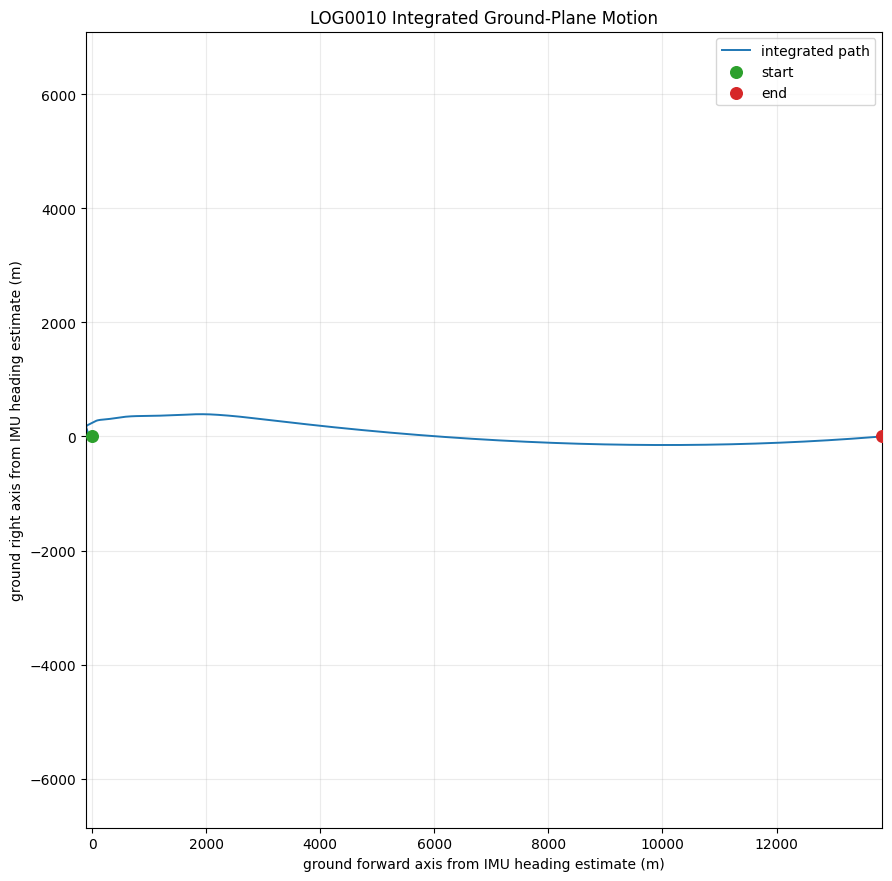

In [20]:
x_limits, y_limits = equal_axis_limits(ground_x_m, ground_y_m, pad_m=max(VEHICLE_LENGTH_M, VEHICLE_WIDTH_M))

fig, ax = plt.subplots(figsize=(9, 9))
ax.plot(ground_x_m, ground_y_m, color="tab:blue", linewidth=1.4, label="integrated path")
ax.scatter(ground_x_m[0], ground_y_m[0], color="tab:green", s=70, label="start", zorder=4)
ax.scatter(ground_x_m[-1], ground_y_m[-1], color="tab:red", s=70, label="end", zorder=4)

start_rect = rectangle_corners([ground_x_m[0], ground_y_m[0]], vehicle_heading_rad[0], VEHICLE_LENGTH_M, VEHICLE_WIDTH_M)
end_rect = rectangle_corners([ground_x_m[-1], ground_y_m[-1]], vehicle_heading_rad[-1], VEHICLE_LENGTH_M, VEHICLE_WIDTH_M)
ax.fill(start_rect[:, 0], start_rect[:, 1], color="tab:green", alpha=0.20)
ax.plot(start_rect[:, 0], start_rect[:, 1], color="tab:green", linewidth=1.2)
ax.fill(end_rect[:, 0], end_rect[:, 1], color="tab:red", alpha=0.20)
ax.plot(end_rect[:, 0], end_rect[:, 1], color="tab:red", linewidth=1.2)

ax.set_title(f"{log_id} Integrated Ground-Plane Motion")
ax.set_xlabel("ground forward axis from IMU heading estimate (m)")
ax.set_ylabel("ground right axis from IMU heading estimate (m)")
ax.set_xlim(*x_limits)
ax.set_ylim(*y_limits)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.25)
ax.legend(loc="best")
plt.tight_layout()
plt.show()


## Interactive Vehicle Simulation

In [21]:
sim_frame_count = min(SIMULATION_MAX_FRAMES, len(imu_adjusted))
sim_indices = np.unique(np.linspace(0, len(imu_adjusted) - 1, sim_frame_count).astype(int))


def draw_vehicle_frame(sample_idx, ax):
    sample_idx = int(sample_idx)
    center = np.array([ground_x_m[sample_idx], ground_y_m[sample_idx]])
    heading = vehicle_heading_rad[sample_idx]
    corners = rectangle_corners(center, heading, VEHICLE_LENGTH_M, VEHICLE_WIDTH_M)
    forward_arrow = np.array([np.cos(heading), np.sin(heading)]) * VEHICLE_LENGTH_M * 0.65

    ax.plot(ground_x_m, ground_y_m, color="0.78", linewidth=1.0, label="full path")
    ax.plot(ground_x_m[: sample_idx + 1], ground_y_m[: sample_idx + 1], color="tab:blue", linewidth=1.8, label="path to frame")
    ax.fill(corners[:, 0], corners[:, 1], color="tab:orange", alpha=0.30)
    ax.plot(corners[:, 0], corners[:, 1], color="tab:orange", linewidth=2.0)
    ax.arrow(
        center[0],
        center[1],
        forward_arrow[0],
        forward_arrow[1],
        color="tab:red",
        width=max(0.03, VEHICLE_WIDTH_M * 0.035),
        head_width=max(0.18, VEHICLE_WIDTH_M * 0.22),
        length_includes_head=True,
        zorder=5,
    )
    ax.scatter(center[0], center[1], color="black", s=20, zorder=6)
    ax.set_xlim(*x_limits)
    ax.set_ylim(*y_limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("ground forward axis (m)")
    ax.set_ylabel("ground right axis (m)")
    ax.set_title(
        f"{log_id}  t={elapsed_s[sample_idx]:.2f} s  "
        f"heading={vehicle_heading_deg[sample_idx]:.1f} deg"
    )
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")


if widgets is None:
    print("ipywidgets is not installed; showing start, middle, and end frames instead.")
    preview_indices = [sim_indices[0], sim_indices[len(sim_indices) // 2], sim_indices[-1]]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for preview_idx, axis in zip(preview_indices, axes):
        draw_vehicle_frame(preview_idx, axis)
    plt.tight_layout()
    plt.show()
else:
    slider = widgets.IntSlider(
        value=0,
        min=0,
        max=len(sim_indices) - 1,
        step=1,
        description="Frame",
        continuous_update=False,
        layout=widgets.Layout(width="75%"),
    )
    time_label = widgets.Label()
    sim_output = widgets.Output()

    def render_sim_frame(frame_number):
        sample_idx = int(sim_indices[int(frame_number)])
        time_label.value = f"sample {sample_idx:,} / {len(imu_adjusted) - 1:,}; elapsed {elapsed_s[sample_idx]:.2f} s"
        with sim_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(8, 8))
            draw_vehicle_frame(sample_idx, ax)
            plt.tight_layout()
            plt.show()

    slider.observe(lambda change: render_sim_frame(change["new"]), names="value")
    display(widgets.VBox([slider, time_label, sim_output]))
    render_sim_frame(slider.value)


## Final Rest Error

In [22]:
end_rest_adjusted = imu_adjusted.loc[end_rest_mask]

final_accel_error_g = end_rest_adjusted[accel_adj_g_cols].mean()
final_accel_error_mps2 = end_rest_adjusted[accel_adj_mps2_cols].mean()
final_velocity_error_mps = end_rest_adjusted[velocity_cols].mean()
final_velocity_error_mph = final_velocity_error_mps * MPS_TO_MPH

print("Final acceleration error during end-rest window (g):")
print(vector_summary(final_accel_error_g, "g").to_string(float_format=lambda value: f"{value:.6f}"))
print("\nFinal acceleration error during end-rest window (m/s^2):")
print(vector_summary(final_accel_error_mps2, "m/s^2").to_string(float_format=lambda value: f"{value:.6f}"))
print("\nFinal velocity error during end-rest window (m/s):")
print(vector_summary(final_velocity_error_mps, "m/s").to_string(float_format=lambda value: f"{value:.6f}"))
print("\nFinal velocity error during end-rest window (mph):")
print(vector_summary(final_velocity_error_mph, "mph").to_string(float_format=lambda value: f"{value:.6f}"))

error_table = pd.DataFrame(
    {
        "accel_error_g": final_accel_error_g.to_numpy(),
        "accel_error_mps2": final_accel_error_mps2.to_numpy(),
        "velocity_error_mps": final_velocity_error_mps.to_numpy(),
        "velocity_error_mph": final_velocity_error_mph.to_numpy(),
    },
    index=AXES,
)
display(error_table)


Final acceleration error during end-rest window (g):
accel_x_adj_g   -0.023706
accel_y_adj_g    0.020750
accel_z_adj_g    0.005376
norm             0.031960

Final acceleration error during end-rest window (m/s^2):
accel_x_adj_mps2   -0.232478
accel_y_adj_mps2    0.203487
accel_z_adj_mps2    0.052722
norm                0.313421

Final velocity error during end-rest window (m/s):
vel_x_mps    -21.550608
vel_y_mps   -108.783488
vel_z_mps      0.755828
norm         110.900168

Final velocity error during end-rest window (mph):
vel_x_mps    -48.207337
vel_y_mps   -243.341733
vel_z_mps      1.690740
norm         248.076611


,accel_error_g,accel_error_mps2,velocity_error_mps,velocity_error_mph
x,-0.023706,-0.232478,-21.550608,-48.207337
y,0.020750,0.203487,-108.783488,-243.341733
z,0.005376,0.052722,0.755828,1.690740


## Quick Plots

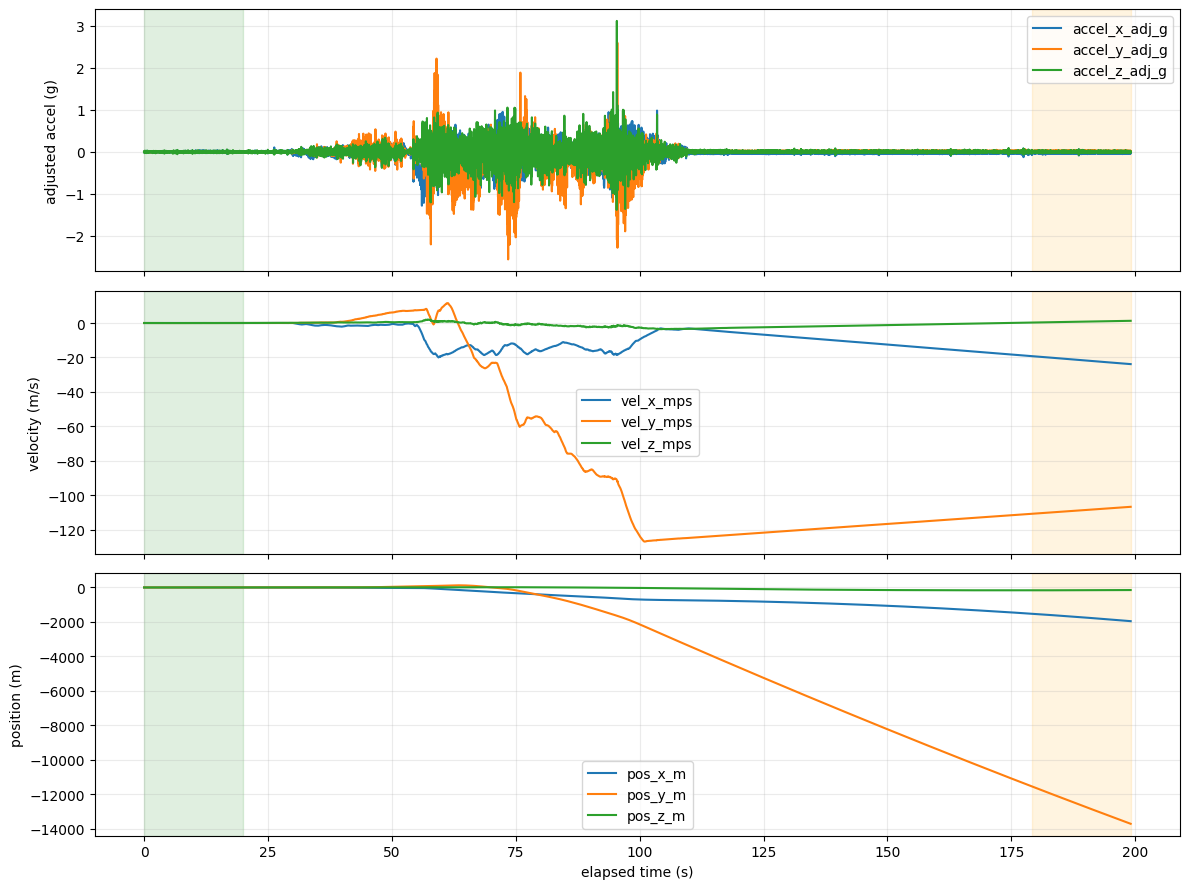

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

imu_adjusted.plot(x="elapsed_s", y=accel_adj_g_cols, ax=axes[0])
axes[0].set_ylabel("adjusted accel (g)")
axes[0].axvspan(baseline_segment["start_s"], baseline_segment["end_s"], alpha=0.12, color="green")
axes[0].axvspan(end_rest_segment["start_s"], end_rest_segment["end_s"], alpha=0.12, color="orange")

imu_adjusted.plot(x="elapsed_s", y=velocity_cols, ax=axes[1])
axes[1].set_ylabel("velocity (m/s)")
axes[1].axvspan(baseline_segment["start_s"], baseline_segment["end_s"], alpha=0.12, color="green")
axes[1].axvspan(end_rest_segment["start_s"], end_rest_segment["end_s"], alpha=0.12, color="orange")

imu_adjusted.plot(x="elapsed_s", y=position_cols, ax=axes[2])
axes[2].set_ylabel("position (m)")
axes[2].set_xlabel("elapsed time (s)")
axes[2].axvspan(baseline_segment["start_s"], baseline_segment["end_s"], alpha=0.12, color="green", label="baseline")
axes[2].axvspan(end_rest_segment["start_s"], end_rest_segment["end_s"], alpha=0.12, color="orange", label="end rest")

for axis in axes:
    axis.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()
